> Paths here point at a flat working folder (`generated_sequences/`, `dna/`,
> `pdbqt/`, `output/`, `template/`), not at this repo's layout. The folders under
> `data/` use the same names, so copy them into one folder to re-run. See
> `docs/RERUN.md`.
>
> Code cells and stored outputs are as they were run. Only markdown was fixed
> where it contradicted the code.


# Stage 3 — Thermodynamic + Diversity Filtering

**Project:** DNA-based electrochemical sensor for IQS  
**Input:** `./generated_sequences/stage2_filtered.csv` (2,000 sequences from Stage 2)  
**Output:**
- `./generated_sequences/stage3_candidates.csv` — 500 sequences (full filtered pool)
- `./generated_sequences/stage3_for_docking.csv` — top 100 sequences (for Vina)
- `./generated_sequences/sequences_for_structure.txt` — top 100 sequences (for the fiber-model builder)

---
### What this notebook does:

**Step 3.1 — SantaLucia ΔG filter**  
Calculates accurate duplex free energy using nearest-neighbor thermodynamics.  
Reference: SantaLucia J. (1998) PNAS 95(4):1460–1465  
Removes sequences that are thermodynamically too unstable or too rigid.  
2,000 → 1,654 sequences

**Step 3.2 — Edit distance diversity filter**  
Removes sequences that are too similar to each other using Levenshtein distance.  
Keeps top 500 diverse sequences.

**Step 3.3 — Final reduction**  
Takes top 100 by total score for manual PDB structure generation and Vina docking.

---
### No external tools needed — pure Python only.
No Vina, no obabel, no 3D structure generation.

## Cell 1 — Import Libraries

In [1]:
import os
import math
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries loaded.")

Libraries loaded.


## Cell 2 — Settings

In [2]:
# ── INPUT / OUTPUT ─────────────────────────────────────────────
INPUT_FILE       = os.path.join("generated_sequences", "stage2_filtered.csv")

# Stage 3 full output (500 sequences)
OUTPUT_CSV       = os.path.join("generated_sequences", "stage3_candidates.csv")

# Final 100 for docking
OUTPUT_DOCKING   = os.path.join("generated_sequences", "stage3_for_docking.csv")
OUTPUT_TXT       = os.path.join("generated_sequences", "sequences_for_structure.txt")

# ── STEP 3.1 — SantaLucia ΔG filter ───────────────────────────
# ΔG range to keep (kcal/mol at 25°C)
# Reference: SantaLucia J. (1998) PNAS 95(4):1460-1465
# DG_MAX = -5.0  : above this = duplex too unstable at room temperature
# DG_MIN = -35.0 : below this = excessively GC-rich, reduced groove accessibility
# Range chosen based on distribution of generated pool (see plot below)
DG_MIN = -35.0
DG_MAX =  -5.0

# ── STEP 3.2 — Diversity filter ───────────────────────────────
# Minimum Levenshtein edit distance between any two kept sequences
# 4 is appropriate for variable-length sequences (12-22 bases)
MIN_EDIT_DIST       = 4
MAX_AFTER_DIVERSITY = 500    # keep this many sequences

# ── STEP 3.3 — Final reduction ────────────────────────────────
# How many sequences to take forward for PDB generation + Vina docking
# These will be prepared manually via w3DNA website
FINAL_FOR_DOCKING = 100

# ───────────────────────────────────────────────────────────────
print("Settings loaded.")
print(f"Input          : {INPUT_FILE}")
print(f"ΔG range       : {DG_MIN} to {DG_MAX} kcal/mol")
print(f"Min edit dist  : {MIN_EDIT_DIST}")
print(f"Pool target    : {MAX_AFTER_DIVERSITY} sequences")
print(f"Final output   : {FINAL_FOR_DOCKING} sequences for docking")

Settings loaded.
Input          : generated_sequences\stage2_filtered.csv
ΔG range       : -35.0 to -5.0 kcal/mol
Min edit dist  : 4
Pool target    : 500 sequences
Final output   : 100 sequences for docking


## Cell 3 — Load Data

In [3]:
if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(
        f"Cannot find: {INPUT_FILE}\n"
        f"Please run Stage 2 notebook first."
    )

df = pd.read_csv(INPUT_FILE)

# Sort by total_score best first
df = df.sort_values('total_score', ascending=False).reset_index(drop=True)

print(f"Loaded {len(df)} sequences from Stage 2.")
print(f"Score range: {df['total_score'].min():.4f} – {df['total_score'].max():.4f}")
print(f"Columns: {list(df.columns)}")
print()
df.head(3)

Loaded 2000 sequences from Stage 2.
Score range: 0.6803 – 1.0000
Columns: ['sequence', 'reverse_comp', 'length', 'gc_content', 'g_count', 'c_count', 'a_count', 't_count', 'purine_fraction', 'gg_steps', 'ga_ag_steps', 'tm_celsius', 'score_tm', 'iqs_raw', 'score_iqs', 'total_score', 'rank']



,sequence,reverse_comp,length,gc_content,g_count,c_count,a_count,t_count,purine_fraction,gg_steps,ga_ag_steps,tm_celsius,score_tm,iqs_raw,score_iqs,total_score,rank
0,GGGTATGGAGACGGGAGGGTA,TACCCTCCCGTCTCCATACCC,21,0.6190,12,1,5,3,0.8095,7,5,68,1.0,40.10,1.000000,1.000000,1
1,CAACGGAAGGCCGGGAGGTTAG,CTAACCTCCCGGCCTTCCGTTG,22,0.6364,10,4,6,2,0.7273,5,5,72,1.0,38.55,0.953731,0.972239,2
2,AGACGAGGGAGAACTCGGAAGC,GCTTCCGAGTTCTCCCTCGTCT,22,0.5909,9,4,8,1,0.7727,3,9,70,1.0,38.35,0.947761,0.968657,3


## Cell 4 — Step 3.1: SantaLucia ΔG Calculation

**Reference:** SantaLucia J. (1998) PNAS 95(4):1460–1465  
Nearest-neighbor model: `ΔG = ΔH − T × (ΔS / 1000)` at T = 298.15 K (25°C)

In [4]:
# ── SantaLucia 1998 nearest-neighbor parameters ────────────────
# Source: Table 2, SantaLucia (1998) PNAS 95(4):1460-1465
# ΔH in kcal/mol, ΔS in cal/mol/K
NN_PARAMS = {
    'AA': ( -7.9, -22.2),
    'AT': ( -7.2, -20.4),
    'TA': ( -7.2, -21.3),
    'CA': ( -8.5, -22.7),
    'GT': ( -8.4, -22.4),
    'CT': ( -7.8, -21.0),
    'GA': ( -8.2, -22.2),
    'CG': (-10.6, -27.2),
    'GC': ( -9.8, -24.4),
    'GG': ( -8.0, -19.9),
    'TT': ( -7.9, -22.2),
    'AC': ( -7.8, -21.0),
    'TC': ( -8.2, -22.2),
    'AG': ( -7.8, -21.0),
    'TG': ( -8.5, -22.7),
    'CC': ( -8.0, -19.9),
}

# Initiation parameters (SantaLucia 1998, Table 2)
INIT_AT  = ( 2.3,  4.1)   # ΔH, ΔS — terminal A or T
INIT_GC  = ( 0.1, -2.8)   # ΔH, ΔS — terminal G or C
T_KELVIN = 298.15          # 25°C


def calculate_delta_g(seq):
    """
    SantaLucia (1998) nearest-neighbor ΔG calculation.
    Returns ΔG in kcal/mol. More negative = more stable duplex.
    """
    total_dH = 0.0
    total_dS = 0.0

    for i in range(len(seq) - 1):
        dinuc = seq[i:i+2]
        if dinuc in NN_PARAMS:
            dH, dS = NN_PARAMS[dinuc]
            total_dH += dH
            total_dS += dS

    for end_base in [seq[0], seq[-1]]:
        if end_base in ('A', 'T'):
            total_dH += INIT_AT[0]
            total_dS += INIT_AT[1]
        else:
            total_dH += INIT_GC[0]
            total_dS += INIT_GC[1]

    # ΔS divided by 1000 to convert cal → kcal
    delta_g = total_dH - T_KELVIN * (total_dS / 1000.0)
    return round(delta_g, 3)


# Calculate for all sequences
print("Calculating SantaLucia ΔG for all sequences...")
df['delta_g'] = df['sequence'].apply(calculate_delta_g)

print("Done.")
print(f"ΔG range : {df['delta_g'].min():.2f} to {df['delta_g'].max():.2f} kcal/mol")
print(f"Average  : {df['delta_g'].mean():.2f} kcal/mol")
print()
print("Example calculations:")
print(f"{'Sequence':<25} {'Len':>4} {'GC%':>6} {'ΔG (kcal/mol)':>14}")
print("-" * 54)
for _, row in df.head(6).iterrows():
    print(f"{row['sequence']:<25} {row['length']:>4} "
          f"{row['gc_content']*100:>5.1f}% {row['delta_g']:>14.3f}")

Calculating SantaLucia ΔG for all sequences...
Done.
ΔG range : -39.43 to -17.50 kcal/mol
Average  : -31.04 kcal/mol

Example calculations:
Sequence                   Len    GC%  ΔG (kcal/mol)
------------------------------------------------------
GGGTATGGAGACGGGAGGGTA       21  61.9%        -32.297
CAACGGAAGGCCGGGAGGTTAG      22  63.6%        -35.501
AGACGAGGGAGAACTCGGAAGC      22  59.1%        -34.514
GACTATGAGGGAAGGAGCCGA       21  57.1%        -31.850
GGAACGGGAGGTAGCTCTGGAG      22  63.6%        -34.621
CCAGAAGATGGAGGGAAGTC        20  55.0%        -29.324


Step 3.1 — SantaLucia ΔG filter results:
  Input             : 2000
  Kept              : 1654
  Removed (unstable): 0  (ΔG > -5.0)
  Removed (rigid)   : 346  (ΔG < -35.0)


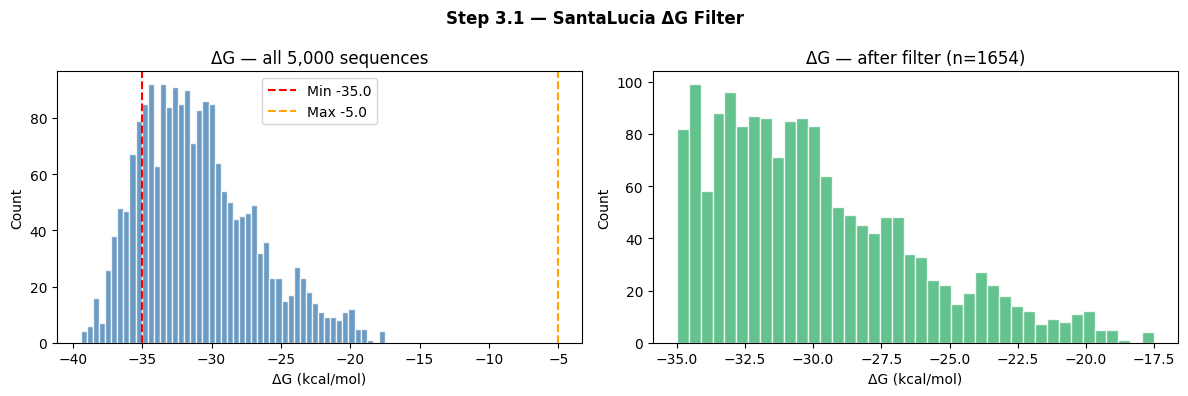

Plot saved.


In [5]:
# Apply ΔG filter
before = len(df)

df_dg = df[
    (df['delta_g'] >= DG_MIN) &
    (df['delta_g'] <= DG_MAX)
].copy()

df_dg = df_dg.sort_values('total_score', ascending=False).reset_index(drop=True)
after = len(df_dg)

too_unstable = (df['delta_g'] > DG_MAX).sum()
too_rigid    = (df['delta_g'] < DG_MIN).sum()

print("Step 3.1 — SantaLucia ΔG filter results:")
print(f"  Input             : {before}")
print(f"  Kept              : {after}")
print(f"  Removed (unstable): {too_unstable}  (ΔG > {DG_MAX})")
print(f"  Removed (rigid)   : {too_rigid}  (ΔG < {DG_MIN})")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Step 3.1 — SantaLucia ΔG Filter', fontweight='bold')

axes[0].hist(df['delta_g'], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].axvline(DG_MIN, color='red',    linestyle='--', label=f'Min {DG_MIN}')
axes[0].axvline(DG_MAX, color='orange', linestyle='--', label=f'Max {DG_MAX}')
axes[0].set_title('ΔG — all 5,000 sequences')
axes[0].set_xlabel('ΔG (kcal/mol)')
axes[0].set_ylabel('Count')
axes[0].legend()

axes[1].hist(df_dg['delta_g'], bins=40, color='mediumseagreen', edgecolor='white', alpha=0.8)
axes[1].set_title(f'ΔG — after filter (n={after})')
axes[1].set_xlabel('ΔG (kcal/mol)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig(
    os.path.join('generated_sequences', 'stage3_dg_filter.png'),
    dpi=150, bbox_inches='tight'
)
plt.show()
print("Plot saved.")

## Cell 5 — Step 3.2: Edit Distance Diversity Filter

Removes sequences that are too similar to each other.  
Uses **Levenshtein edit distance** — works correctly for different length sequences.  

A sequence is kept only if it differs from ALL already-selected sequences  
by at least **MIN_EDIT_DIST** changes.  
Selection always starts from highest-scoring sequences first.

In [6]:
def edit_distance(s1, s2):
    """
    Levenshtein edit distance between two sequences.
    Handles sequences of different lengths correctly.
    Returns minimum number of insertions, deletions,
    or substitutions to transform s1 into s2.
    """
    m, n = len(s1), len(s2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1):
        dp[i][0] = i
    for j in range(n + 1):
        dp[0][j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if s1[i-1] == s2[j-1]:
                dp[i][j] = dp[i-1][j-1]
            else:
                dp[i][j] = 1 + min(
                    dp[i-1][j],
                    dp[i][j-1],
                    dp[i-1][j-1]
                )
    return dp[m][n]


# Quick sanity check
print("Edit distance sanity check:")
tests = [
    ("GCATGCGCAT", "GCATGCGCAT", "identical → 0"),
    ("GCATGCGCAT", "GCATGCGCAA", "1 substitution → 1"),
    ("GCATGCGCAT", "GCATGCGCA",  "1 deletion → 1"),
    ("GCATGCGCAT", "CGTACGCGTA", "very different → 5+"),
]
for s1, s2, desc in tests:
    d = edit_distance(s1, s2)
    print(f"  distance={d}  ({desc})")

Edit distance sanity check:
  distance=0  (identical → 0)
  distance=1  (1 substitution → 1)
  distance=1  (1 deletion → 1)
  distance=5  (very different → 5+)


In [7]:
# Run diversity filter on df_dg
# Already sorted by total_score descending — best sequences selected first
sequences_ranked = df_dg['sequence'].tolist()

print("Running diversity filter...")
print(f"  Input            : {len(sequences_ranked)} sequences")
print(f"  Min edit distance: {MIN_EDIT_DIST}")
print(f"  Target output    : {MAX_AFTER_DIVERSITY} sequences")
print(f"  (may take a few minutes)")
print()

selected_seqs  = []
rejected_count = 0

for i, seq in enumerate(sequences_ranked):

    too_similar = False
    for already_selected in selected_seqs:
        if edit_distance(seq, already_selected) < MIN_EDIT_DIST:
            too_similar = True
            rejected_count += 1
            break

    if not too_similar:
        selected_seqs.append(seq)

    if (i + 1) % 300 == 0:
        print(f"  Processed {i+1:>5}/{len(sequences_ranked)} — "
              f"kept {len(selected_seqs)} so far")

    if len(selected_seqs) >= MAX_AFTER_DIVERSITY:
        print(f"  Reached target of {MAX_AFTER_DIVERSITY} — stopping")
        break

# Build output dataframe
df_diverse = df_dg[df_dg['sequence'].isin(selected_seqs)].copy()
df_diverse = df_diverse.sort_values('total_score', ascending=False).reset_index(drop=True)

print()
print("Diversity filter results:")
print(f"  Input  : {len(sequences_ranked)}")
print(f"  Kept   : {len(df_diverse)}")
print(f"  Removed: {rejected_count} near-duplicates")

Running diversity filter...
  Input            : 1654 sequences
  Min edit distance: 4
  Target output    : 500 sequences
  (may take a few minutes)

  Processed   300/1654 — kept 299 so far
  Reached target of 500 — stopping

Diversity filter results:
  Input  : 1654
  Kept   : 500
  Removed: 2 near-duplicates


## Cell 6 — Save 500-Sequence Pool (Stage 3 Full Output)

In [8]:
# Save full 500-sequence pool to CSV
df_diverse.to_csv(OUTPUT_CSV, index=False)
print(f"✅ CSV saved : {OUTPUT_CSV}")
print(f"   Sequences : {len(df_diverse)}")
print(f"   Columns   : {list(df_diverse.columns)}")

✅ CSV saved : generated_sequences\stage3_candidates.csv
   Sequences : 500
   Columns   : ['sequence', 'reverse_comp', 'length', 'gc_content', 'g_count', 'c_count', 'a_count', 't_count', 'purine_fraction', 'gg_steps', 'ga_ag_steps', 'tm_celsius', 'score_tm', 'iqs_raw', 'score_iqs', 'total_score', 'rank', 'delta_g']


## Cell 7 — Summary Statistics and Plots

STAGE 3 — FILTERING COMPLETE
Stage 2 input           :   2000 sequences
After SantaLucia filter :   1654 sequences
After diversity filter  :    500 sequences

Property                       All 5k    Final
----------------------------------------------
  GC content (avg)              0.625    0.621
  Length (avg)                   19.3     19.5
  ΔG (avg, kcal/mol)           -31.04   -30.98
  Total score (avg)            0.7395   0.8005
  GG steps (avg)                 2.53     3.21

Top 10 sequences by total score:
Rank  Sequence                    GC%       ΔG    Score
--------------------------------------------------------
1     GGGTATGGAGACGGGAGGGTA     61.9%   -32.30   1.0000
2     AGACGAGGGAGAACTCGGAAGC    59.1%   -34.51   0.9687
3     GACTATGAGGGAAGGAGCCGA     57.1%   -31.85   0.9499
4     GGAACGGGAGGTAGCTCTGGAG    63.6%   -34.62   0.9490
5     CCAGAAGATGGAGGGAAGTC      55.0%   -29.32   0.9310
6     TTCCACGGGCTGGAGGGAAGC     66.7%   -34.85   0.9167
7     AGGAGCGGAACTGGGACCGG   

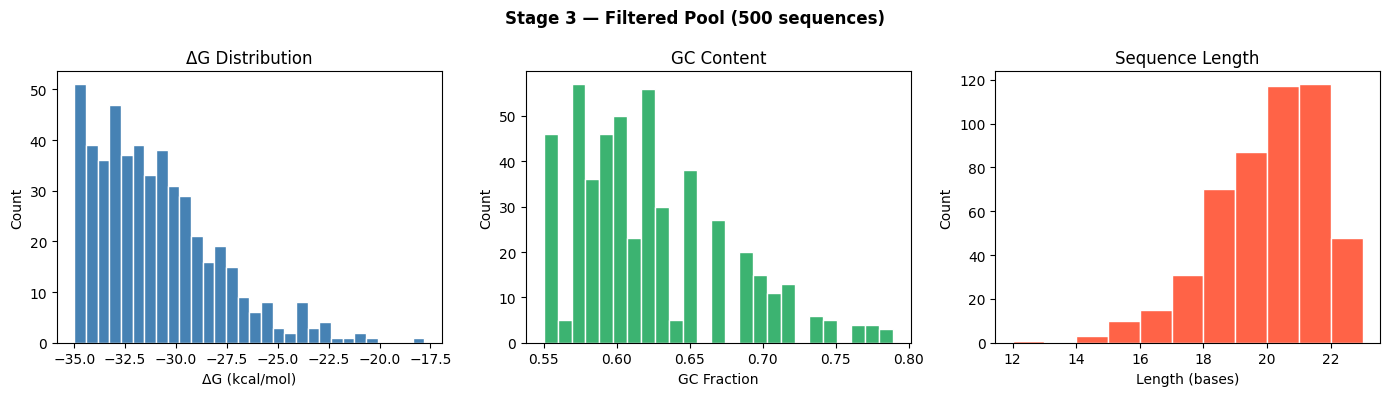

Plot saved.


In [9]:
print("=" * 55)
print("STAGE 3 — FILTERING COMPLETE")
print("=" * 55)
print(f"Stage 2 input           : {len(df):>6} sequences")
print(f"After SantaLucia filter : {len(df_dg):>6} sequences")
print(f"After diversity filter  : {len(df_diverse):>6} sequences")
print()
print(f"{'Property':<28} {'All 5k':>8} {'Final':>8}")
print("-" * 46)
for label, col, fmt in [
    ('GC content (avg)',     'gc_content',  '{:.3f}'),
    ('Length (avg)',         'length',      '{:.1f}'),
    ('ΔG (avg, kcal/mol)',   'delta_g',     '{:.2f}'),
    ('Total score (avg)',    'total_score', '{:.4f}'),
    ('GG steps (avg)',       'gg_steps',    '{:.2f}'),
]:
    all_val   = fmt.format(df[col].mean())
    final_val = fmt.format(df_diverse[col].mean())
    print(f"  {label:<26} {all_val:>8} {final_val:>8}")

print()
print("Top 10 sequences by total score:")
print(f"{'Rank':<5} {'Sequence':<25} {'GC%':>5} {'ΔG':>8} {'Score':>8}")
print("-" * 56)
for i, row in df_diverse.head(10).iterrows():
    print(
        f"{i+1:<5} {row['sequence']:<25} "
        f"{row['gc_content']*100:>4.1f}% "
        f"{row['delta_g']:>8.2f} "
        f"{row['total_score']:>8.4f}"
    )

# Plots
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Stage 3 — Filtered Pool (500 sequences)', fontweight='bold')

axes[0].hist(df_diverse['delta_g'], bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('ΔG Distribution')
axes[0].set_xlabel('ΔG (kcal/mol)')
axes[0].set_ylabel('Count')

axes[1].hist(df_diverse['gc_content'], bins=25, color='mediumseagreen', edgecolor='white')
axes[1].set_title('GC Content')
axes[1].set_xlabel('GC Fraction')
axes[1].set_ylabel('Count')

axes[2].hist(df_diverse['length'], bins=range(12, 24), color='tomato', edgecolor='white')
axes[2].set_title('Sequence Length')
axes[2].set_xlabel('Length (bases)')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.savefig(
    os.path.join('generated_sequences', 'stage3_partA_summary.png'),
    dpi=150, bbox_inches='tight'
)
plt.show()
print("Plot saved.")

## Cell 8 — Final Reduction to Top 100 for Docking

Takes the top 100 sequences by total score from the 500-sequence pool.  
These will be used for:
1. PDB structure generation via the 3DNA/DSSR fiber-model builder (web.x3dna-dssr.org)
2. Adding hydrogens in Avogadro
3. AutoDock Vina docking using the existing pipeline

Output files:
- `stage3_for_docking.csv` — full data for top 100 (input for Vina pipeline)
- `sequences_for_structure.txt` — sequence list for w3DNA (human-readable)

In [10]:
# Take top FINAL_FOR_DOCKING sequences from the 500 pool
# df_diverse is already sorted by total_score best first
df_top = df_diverse.head(FINAL_FOR_DOCKING).copy()
df_top = df_top.reset_index(drop=True)

print(f"Selected top {len(df_top)} sequences for docking")
print(f"Score range : {df_top['total_score'].min():.4f} – {df_top['total_score'].max():.4f}")
print(f"ΔG range    : {df_top['delta_g'].min():.2f} – {df_top['delta_g'].max():.2f} kcal/mol")
print(f"Length range: {df_top['length'].min()} – {df_top['length'].max()} bases")
print()
print("Length distribution:")
print(df_top['length'].value_counts().sort_index().to_string())
print()

# ── Save CSV (full data for Vina pipeline) ─────────────────────
df_top.to_csv(OUTPUT_DOCKING, index=False)
print(f"✅ CSV saved : {OUTPUT_DOCKING}")

# ── Save plain text for w3DNA / Avogadro ──────────────────────
# This is the file you use when generating PDB structures
# Go to web3dna.rutgers.edu, paste each sequence, download PDB
with open(OUTPUT_TXT, 'w') as f:
    f.write(f"# Top {len(df_top)} sequences for PDB structure generation\n")
    f.write(f"# Use w3DNA website: web3dna.rutgers.edu\n")
    f.write(f"# Generate B-form dsDNA PDB for each sequence\n")
    f.write(f"# Then add hydrogens in Avogadro before Vina docking\n")
    f.write("-" * 65 + "\n")
    f.write(f"# Format: rank | sequence | length | GC% | dG | score\n")
    f.write("-" * 65 + "\n")
    for i, row in df_top.iterrows():
        f.write(
            f"{i+1:>4}. {row['sequence']:<25} "
            f"len={row['length']:>2} "
            f"GC={row['gc_content']*100:>4.1f}% "
            f"dG={row['delta_g']:>7.2f} "
            f"score={row['total_score']:.4f}\n"
        )

print(f"✅ TXT saved : {OUTPUT_TXT}")
print()
print("Top 10 candidates for docking:")
print(f"{'Rank':<5} {'Sequence':<25} {'Len':>4} {'GC%':>6} {'dG':>8} {'Score':>8}")
print("-" * 60)
for i, row in df_top.head(10).iterrows():
    print(
        f"{i+1:<5} {row['sequence']:<25} "
        f"{row['length']:>4} "
        f"{row['gc_content']*100:>5.1f}% "
        f"{row['delta_g']:>8.2f} "
        f"{row['total_score']:>8.4f}"
    )

print()
print("=" * 55)
print("STAGE 3 COMPLETE")
print("=" * 55)
print(f"Output files in generated_sequences/:")
print(f"  stage3_candidates.csv        ← 500 sequences (full pool)")
print(f"  stage3_for_docking.csv       ← {len(df_top)} sequences (for Vina)")
print(f"  sequences_for_structure.txt  ← {len(df_top)} sequences (for w3DNA)")
print()
print("Next step:")
print("  1. Open sequences_for_structure.txt")
print("  2. For each sequence, go to web3dna.rutgers.edu")
print("  3. Generate B-form dsDNA PDB structure")
print("  4. Open each PDB in Avogadro → Add Hydrogens → Save")
print("  5. Run Vina docking using your existing pipeline")

Selected top 100 sequences for docking
Score range : 0.8316 – 1.0000
ΔG range    : -34.85 – -24.12 kcal/mol
Length range: 15 – 22 bases

Length distribution:
length
15     1
17     1
18     7
19    14
20    25
21    38
22    14

✅ CSV saved : generated_sequences\stage3_for_docking.csv
✅ TXT saved : generated_sequences\sequences_for_structure.txt

Top 10 candidates for docking:
Rank  Sequence                   Len    GC%       dG    Score
------------------------------------------------------------
1     GGGTATGGAGACGGGAGGGTA       21  61.9%   -32.30   1.0000
2     AGACGAGGGAGAACTCGGAAGC      22  59.1%   -34.51   0.9687
3     GACTATGAGGGAAGGAGCCGA       21  57.1%   -31.85   0.9499
4     GGAACGGGAGGTAGCTCTGGAG      22  63.6%   -34.62   0.9490
5     CCAGAAGATGGAGGGAAGTC        20  55.0%   -29.32   0.9310
6     TTCCACGGGCTGGAGGGAAGC       21  66.7%   -34.85   0.9167
7     AGGAGCGGAACTGGGACCGG        20  70.0%   -33.34   0.9122
8     CGCAGAGTGGAGGAGAAACCC       21  61.9%   -33.18   0.9113
9